# Urban growth cellular automaton: corrected version (2026)

This notebook re-implements the 2024 model in [`../original/`](../original/) with its bugs fixed, and runs it on a **synthetic town**, because the original rasters are confidential.

The model logic lives in [`model.py`](model.py). It has three stages, each adding one driver of urban growth:

| Stage | New urban pixel when… |
|---|---|
| 1. Buildings | exactly 3 of its 8 neighbours are built |
| 2. + Roads | … **or** it is within 4 pixels of a road and has at least 1 built neighbour |
| 3. + Slope | … and, in every case, its slope is at most 15° |

Built pixels never revert, and road pixels are never built on. One iteration is labelled as one year, which is an assumption, not a calibrated rate.

In [1]:
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from model import make_terrain, make_roads, make_buildings, run

elev, slope = make_terrain()
roads = make_roads()
buildings = make_buildings(roads, slope)
dist = distance_transform_edt(~roads)   # distance from every pixel to the nearest road

## Inputs

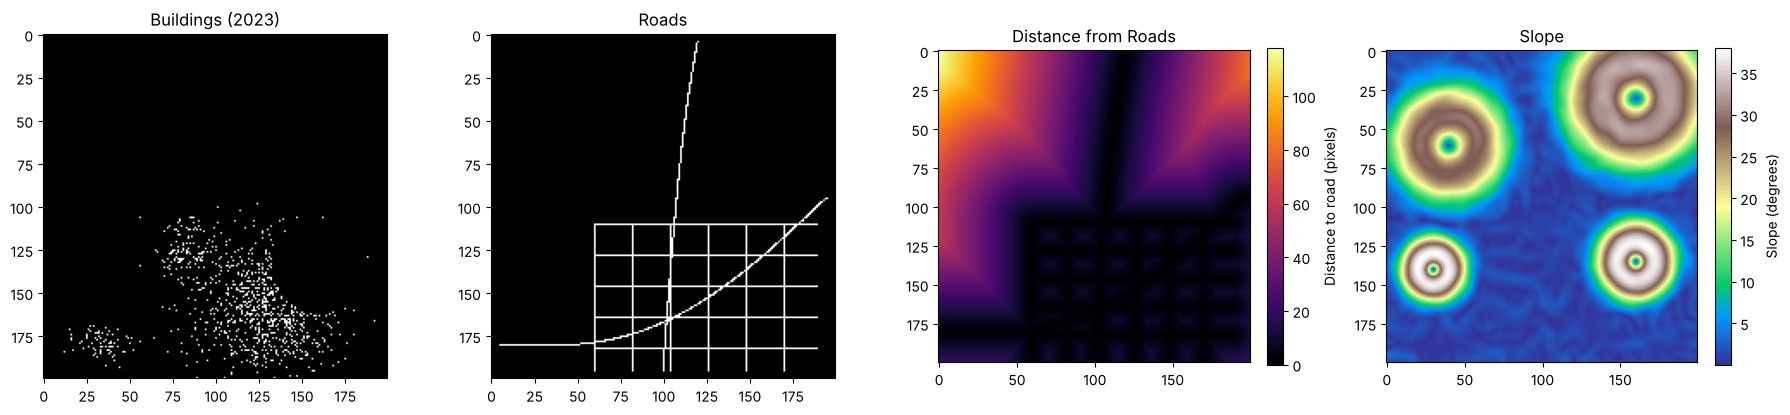

In [2]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.3))
ax[0].imshow(buildings, cmap='gray'); ax[0].set_title('Buildings (2023)')
ax[1].imshow(roads, cmap='gray'); ax[1].set_title('Roads')
im = ax[2].imshow(dist, cmap='inferno'); plt.colorbar(im, ax=ax[2], fraction=.046, label='Distance to road (pixels)'); ax[2].set_title('Distance from Roads')
im = ax[3].imshow(slope, cmap='terrain'); plt.colorbar(im, ax=ax[3], fraction=.046, label='Slope (degrees)'); ax[3].set_title('Slope')
plt.tight_layout(); plt.savefig('../figures/01_inputs.png', dpi=110); plt.show()

## The distance-transform fix

`distance_transform_edt` measures, for every **non-zero** pixel, the distance to the nearest zero pixel. Passing the road mask therefore gives each road pixel's depth *inside* the road. To get every pixel's distance *to* a road, the mask has to be inverted.

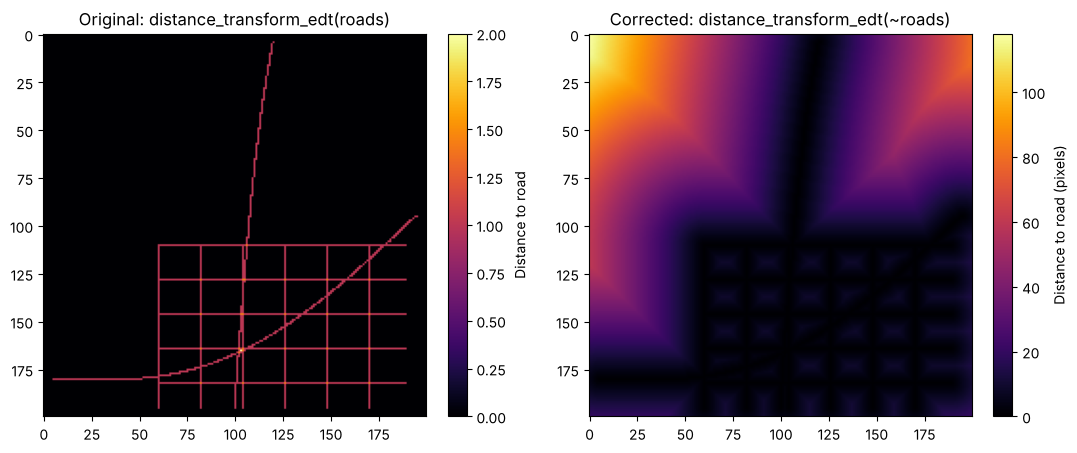

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
im = ax[0].imshow(distance_transform_edt(roads), cmap='inferno'); plt.colorbar(im, ax=ax[0], fraction=.046, label='Distance to road')
ax[0].set_title('Original: distance_transform_edt(roads)')
im = ax[1].imshow(dist, cmap='inferno'); plt.colorbar(im, ax=ax[1], fraction=.046, label='Distance to road (pixels)')
ax[1].set_title('Corrected: distance_transform_edt(~roads)')
plt.tight_layout(); plt.savefig('../figures/02_distance_fix.png', dpi=110); plt.show()

## Running the three stages (2023 → 2029)

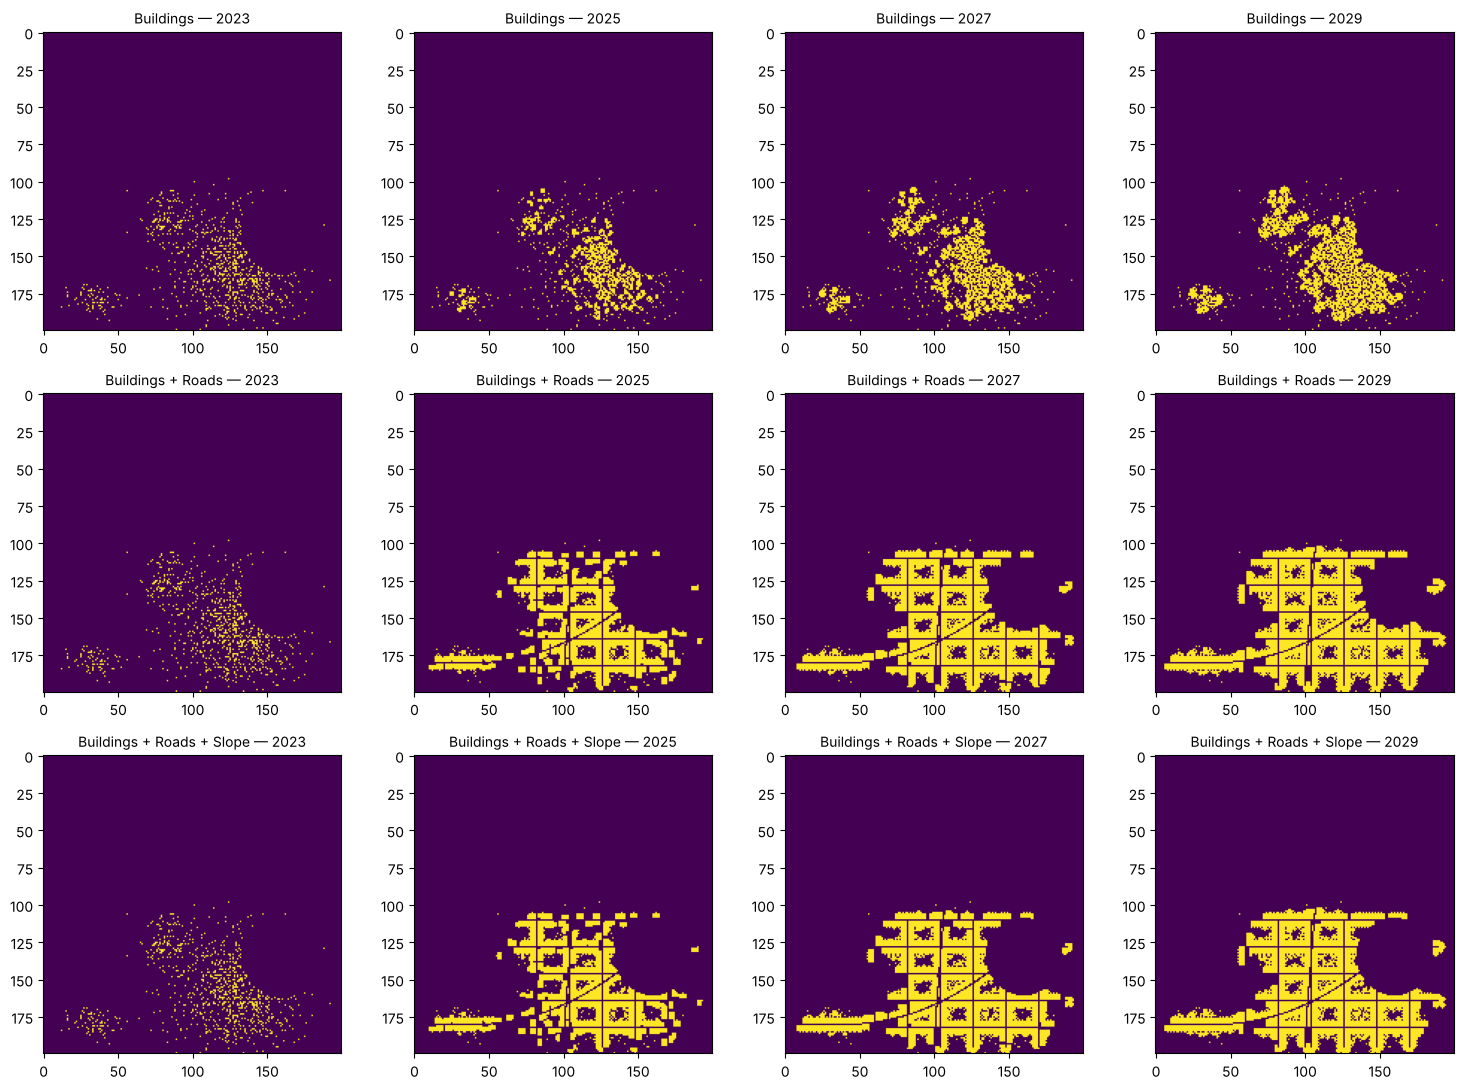

In [4]:
stages = {
    'Buildings': run(buildings, 6),
    'Buildings + Roads': run(buildings, 6, dist=dist),
    'Buildings + Roads + Slope': run(buildings, 6, dist=dist, slope=slope),
}

fig, ax = plt.subplots(3, 4, figsize=(15, 11))
for i, (name, years) in enumerate(stages.items()):
    for j, t in enumerate([0, 2, 4, 6]):
        ax[i, j].imshow(years[t], cmap='viridis')
        ax[i, j].set_title(f'{name} — {2023 + t}', fontsize=10)
plt.tight_layout(); plt.savefig('../figures/03_stages_over_time.png', dpi=110); plt.show()

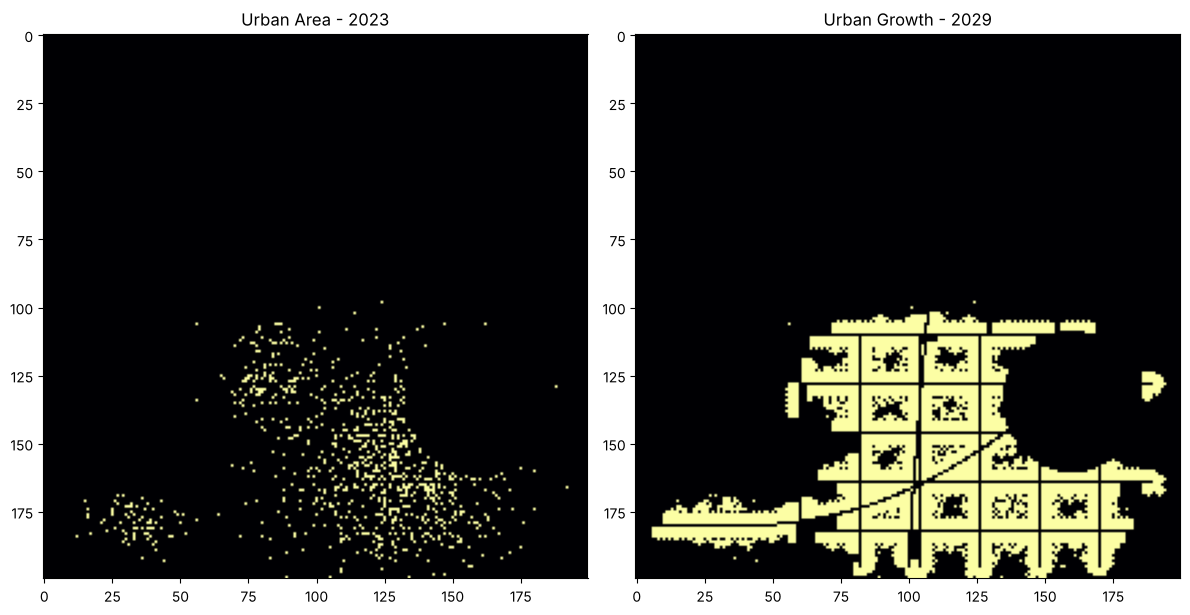

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(buildings, cmap='inferno'); ax[0].set_title('Urban Area - 2023')
ax[1].imshow(stages['Buildings + Roads + Slope'][-1], cmap='inferno'); ax[1].set_title('Urban Growth - 2029')
plt.tight_layout(); plt.savefig('../figures/04_urban_growth_2023_2029.png', dpi=110); plt.show()

## Built-up area per stage

Buildings                        76    106    140    169    197    221    246 ha
Buildings + Roads                76    281    414    498    556    601    641 ha
Buildings + Roads + Slope        76    281    413    493    546    586    620 ha


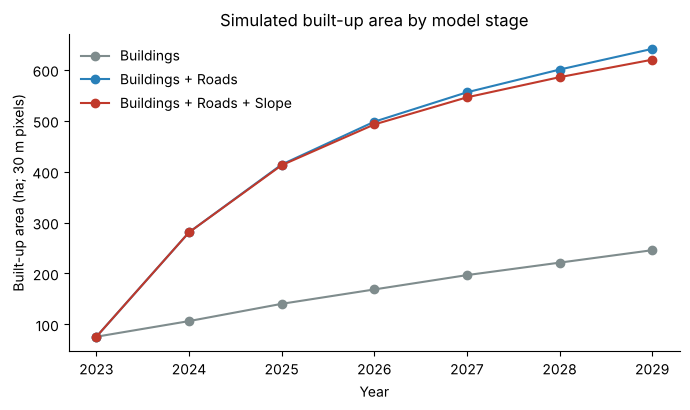

In [6]:
PIXEL_HA = 0.09   # 30 m x 30 m pixel = 900 m² = 0.09 ha

fig, ax = plt.subplots(figsize=(7, 4.2))
for (name, years), color in zip(stages.items(), ['#7f8c8d', '#2980b9', '#c0392b']):
    area = [u.sum() * PIXEL_HA for u in years]
    ax.plot(range(2023, 2030), area, marker='o', label=name, color=color)
    print(f'{name:28s}', ' '.join(f'{a:6.0f}' for a in area), 'ha')
ax.set_xlabel('Year'); ax.set_ylabel('Built-up area (ha; 30 m pixels)')
ax.set_title('Simulated built-up area by model stage')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('../figures/05_growth_curves.png', dpi=110); plt.show()

Roads drive by far the largest increase, and the slope constraint visibly keeps growth off the steep hill on the right (bottom row of the stage figure). The near-quadrupling in the first year of stages 2 and 3 shows that the rules are **not calibrated**: see *Making it more realistic* in the README.